# Cuántos bits hacen falta: BER, variabilidad y cero errores

**Tema 4 · Apartados 4.3 y 4.5 · Demostración orientativa: 10–20 minutos.**

Cambiar el número de bits y el ruido para ver cómo fluctúa la BER estimada y qué permite afirmar una prueba sin errores.

## Cómo experimentar
Ejecuta todo de arriba abajo. Cambia un parámetro, predice qué ocurrirá y vuelve a ejecutar todas las celdas.
En Colab: *Entorno de ejecución → Ejecutar todas*. En Jupyter: *Kernel → Restart Kernel and Run All Cells*.
Los comentarios `#@param` permiten formularios en Colab; en Jupyter puedes editar los valores.

En la web, «Abrir en Colab» abre este cuaderno en el navegador.
La descarga .ipynb permite abrirlo en Jupyter o importarlo en Colab.
La vista HTML muestra resultados guardados; no recalcula las gráficas. Los cambios en Colab no modifican el original.
Los datos se generan en el propio cuaderno. La semilla reproduce una realización, no elimina la variabilidad estadística.
No se instalan paquetes ni se descargan datos. Solo se necesitan NumPy y Matplotlib.

## Modelo y pregunta

Usamos BPSK normalizada, un bit por símbolo, ruido gaussiano independiente y receptor de signo.
Q(z) es la probabilidad de que una normal estándar supere z. `erfc` es la función error complementaria,
una función matemática con la que Python evalúa esa probabilidad de cola.
Con gamma=Eb/N0 lineal, la BER de referencia es
$$p=Q(\sqrt{2\gamma})=\tfrac12\operatorname{erfc}(\sqrt\gamma),\qquad \gamma=10^{(Eb/N0)_{dB}/10}.$$
Es la probabilidad de que el ruido cruce el umbral. Eb/N0 usa el punto y la normalización real de la teoría:
la SNR por muestra es 2 gamma; no se iguala a Eb/N0.

Cada indicador de error es Bernoulli: 1 con probabilidad p y 0 si el bit es correcto.
Su suma K en N decisiones tiene distribución binomial y la BER estimada es K/N.
Para agilizar el ejemplo generamos **recuentos binomiales equivalentes a N decisiones independientes**;
no transmitimos un enlace codificado ni ejecutamos un decodificador.
La desviación de K/N entre pruebas es sqrt(p(1−p)/N). Una barra ±una desviación no es una garantía ni un intervalo del 95%.

Si K=0, la cota unilateral de confianza del 95% es p_sup=1−0.05^(1/N), aproximadamente 3/N.
Se obtiene imponiendo P(K=0)=(1−p_sup)^N=0.05. Una BER mayor produciría cero errores con probabilidad inferior a 5%.
Se requieren errores independientes con probabilidad constante.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})

## Parámetros

Cambia un valor cada vez. Los rangos y las unidades aparecen en los comentarios.

In [2]:
#@title Parámetros
Eb_N0_db = 4.3 #@param {type:"slider", min:0, max:10, step:0.1}
n_bits = 10000 #@param {type:"integer"}
n_repeticiones = 400 #@param {type:"integer"}
semilla = 2026 #@param {type:"integer"}
assert 0 <= Eb_N0_db <= 10
assert isinstance(n_bits,int) and 1000 <= n_bits <= 100000
assert isinstance(n_repeticiones,int) and 100 <= n_repeticiones <= 2000
assert isinstance(semilla,int) and 0 <= semilla <= 999999

## 1. Una curva obtenida con un número finito de bits
Línea: referencia teórica. Puntos: recuentos generados en pruebas de N bits.
Las barras sustituyen p por K/N para estimar sigma, y pueden ser poco fiables con muy pocos errores.
Si K=0, no se dibuja cero en una escala logarítmica: el triángulo marca la cota 95%, **no una BER medida**.
El punto naranja corresponde al Eb/N0 elegido; no tiene por qué coincidir con los puntos azules.

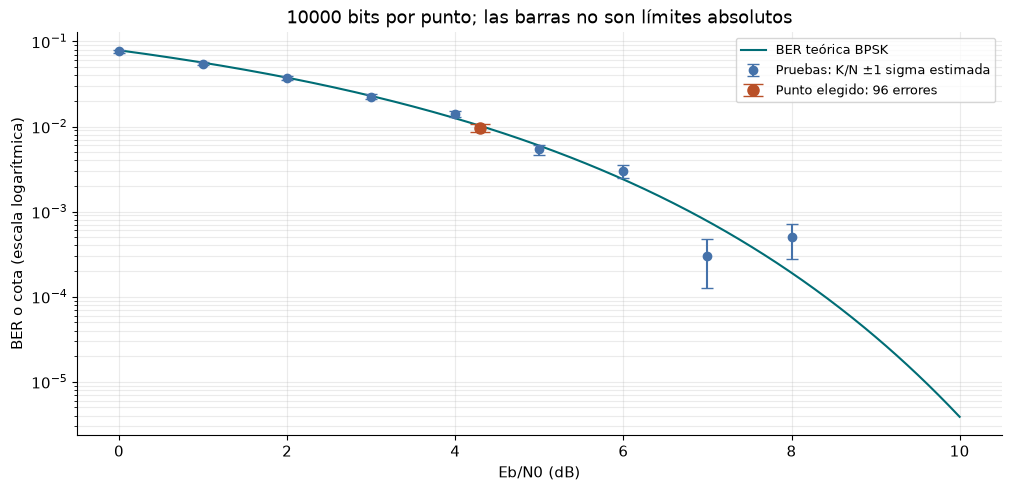

En el punto elegido: p del modelo = 0.0101665; E[K] = 101.67.
Esta prueba: K = 96; frecuencia K/N = 0.0096.
Desviación real entre pruebas: 0.00100315; estimada: 0.000975082.


In [3]:
ber=lambda db:.5*math.erfc(math.sqrt(10**(db/10)))
p_real=ber(Eb_N0_db);rng=np.random.default_rng(semilla)
K=int(rng.binomial(n_bits,p_real));p_est=K/n_bits
sigma_real=math.sqrt(p_real*(1-p_real)/n_bits)
sigma_est=math.sqrt(p_est*(1-p_est)/n_bits)
cota=-math.expm1(math.log(.05)/n_bits)
dbs=np.arange(0,9,dtype=float);ps=np.array([ber(db) for db in dbs])
cuentas=np.random.default_rng(semilla+1).binomial(n_bits,ps)
est=cuentas/n_bits;sd_est=np.sqrt(est*(1-est)/n_bits)
fig,ax=plt.subplots(figsize=(10,4.8),layout='constrained')
eje=np.linspace(0,10,401);ax.semilogy(eje,[ber(db) for db in eje],c='#006d75',label='BER teórica BPSK')
positivos=cuentas>0
ax.errorbar(dbs[positivos],est[positivos],yerr=sd_est[positivos],fmt='o',capsize=4,c='#4572aa',label='Pruebas: K/N ±1 sigma estimada')
if np.any(~positivos):ax.scatter(dbs[~positivos],np.full(np.sum(~positivos),cota),marker='v',c='#617583',label='0 errores: cota 95%')
if K:ax.errorbar([Eb_N0_db],[p_est],yerr=[sigma_est],fmt='o',ms=8,capsize=7,c='#b95028',label=f'Punto elegido: {K} errores')
else:ax.scatter([Eb_N0_db],[cota],marker='v',s=100,c='#b95028',label='Punto elegido: 0 errores, cota')
ax.set(xlabel='Eb/N0 (dB)',ylabel='BER o cota (escala logarítmica)',title=f'{n_bits} bits por punto; las barras no son límites absolutos')
ax.legend(fontsize=9);ax.grid(alpha=.25,which='both');plt.show()
print(f'En el punto elegido: p del modelo = {p_real:.6g}; E[K] = {n_bits*p_real:.2f}.')
print(f'Esta prueba: K = {K}; frecuencia K/N = {p_est:.6g}.')
print(f'Desviación real entre pruebas: {sigma_real:.6g}; estimada: {sigma_est:.6g}.')
if K==0:print(f'La desviación estimada es cero, pero no prueba precisión perfecta. Cota 95% = {cota:.6g}.')

## 2. Repetir la prueba muestra qué significa la varianza
Conservamos el Eb/N0 elegido y repetimos el experimento; cada repetición usa N bits nuevos.
Las barras forman un histograma de K/N; su altura se divide por la anchura para que el área sea uno.
La línea negra es p del modelo; la zona sombreada marca p ±una desviación **real** de las frecuencias.
Con pocos errores esperados, la distribución es discreta y asimétrica: no presuponemos una campana normal.

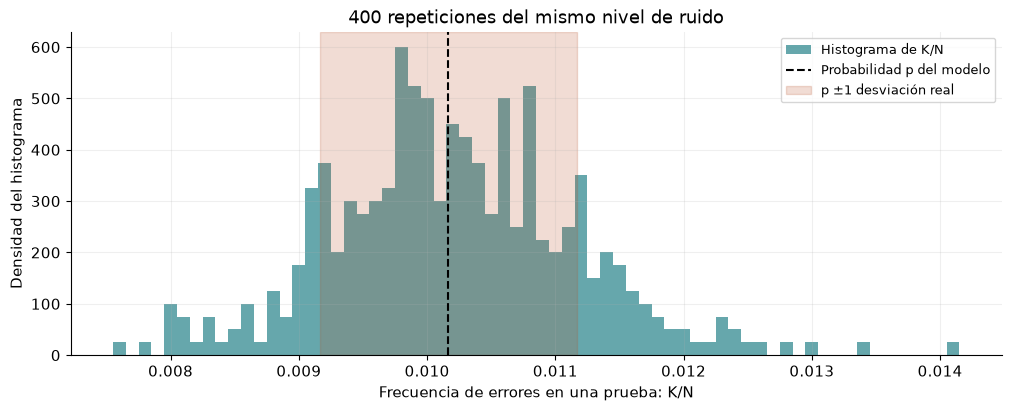

Media de las frecuencias: 0.010206; p = 0.0101665.
Varianza observada: 9.23573e-07; teoría: 1.00632e-06.
Pruebas sin errores: 0 de 400.


In [4]:
cuentas_rep=np.random.default_rng(semilla+2).binomial(n_bits,p_real,n_repeticiones)
frecuencias=cuentas_rep/n_bits
min_k=int(cuentas_rep.min());max_k=int(cuentas_rep.max());bins=np.arange(min_k-.5,max_k+1.5)/n_bits
fig,ax=plt.subplots(figsize=(10,4),layout='constrained')
ax.hist(frecuencias,bins=bins,density=True,color='#006d75',alpha=.6,label='Histograma de K/N')
ax.axvline(p_real,c='black',ls='--',label='Probabilidad p del modelo')
ax.axvspan(max(0,p_real-sigma_real),p_real+sigma_real,color='#b95028',alpha=.2,label='p ±1 desviación real')
ax.set(xlabel='Frecuencia de errores en una prueba: K/N',ylabel='Densidad del histograma',title=f'{n_repeticiones} repeticiones del mismo nivel de ruido')
ax.legend(fontsize=9);ax.grid(alpha=.2);plt.show()
var_teorica=p_real*(1-p_real)/n_bits
print(f'Media de las frecuencias: {frecuencias.mean():.6g}; p = {p_real:.6g}.')
print(f'Varianza observada: {frecuencias.var(ddof=1):.6g}; teoría: {var_teorica:.6g}.')
print(f'Pruebas sin errores: {np.sum(cuentas_rep==0)} de {n_repeticiones}.')

## 3. ¿Qué dice una prueba con cero errores?
Esta figura teórica pregunta por una prueba que hubiera dado K=0; no sustituye el resultado anterior.
A la izquierda, P(K=0) disminuye al crecer la BER real. En la cota 95%, vale 0.05.
A la derecha, la cota baja con N: cero errores entre un millón de bits informa más que cero entre mil.
El 95% se refiere a la cobertura del procedimiento en pruebas repetidas; no garantiza un límite absoluto en esta prueba.

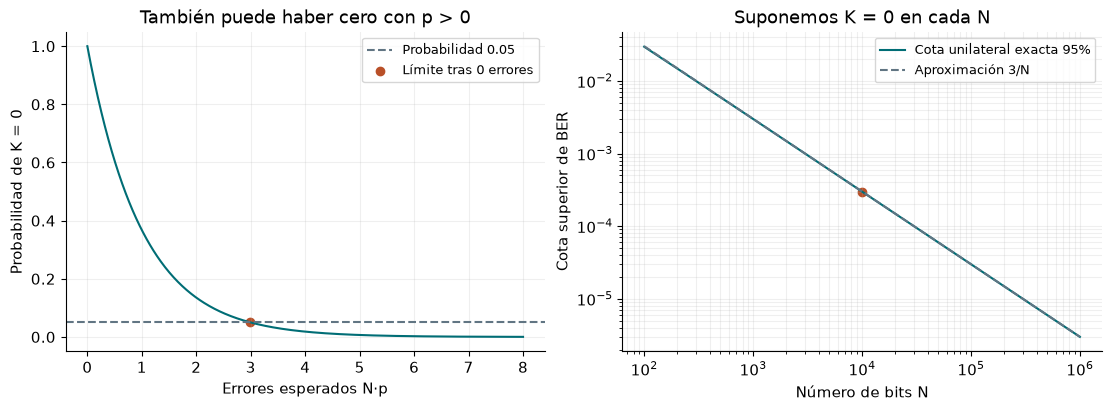

Si K=0 en N=10000: cota exacta 0.000299528; 3/N=0.0003.


In [5]:
p_eje=np.linspace(0,8/n_bits,501);p_cero=np.exp(n_bits*np.log1p(-p_eje))
Ns=np.unique(np.geomspace(100,1000000,300).astype(int));upper=-np.expm1(np.log(.05)/Ns)
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
axes[0].plot(p_eje*n_bits,p_cero,c='#006d75')
axes[0].axhline(.05,c='#617583',ls='--',label='Probabilidad 0.05')
axes[0].scatter([cota*n_bits],[.05],c='#b95028',label='Límite tras 0 errores')
axes[0].set(xlabel='Errores esperados N·p',ylabel='Probabilidad de K = 0',title='También puede haber cero con p > 0');axes[0].legend(fontsize=9)
axes[1].loglog(Ns,upper,c='#006d75',label='Cota unilateral exacta 95%')
axes[1].loglog(Ns,3/Ns,c='#617583',ls='--',label='Aproximación 3/N');axes[1].scatter([n_bits],[cota],c='#b95028')
axes[1].set(xlabel='Número de bits N',ylabel='Cota superior de BER',title='Suponemos K = 0 en cada N');axes[1].legend(fontsize=9)
for ax in axes:ax.grid(alpha=.2,which='both')
plt.show();print(f'Si K=0 en N={n_bits}: cota exacta {cota:.6g}; 3/N={3/n_bits:.6g}.')

## Antes de mirar la explicación

1. Multiplica N por diez conservando Eb/N0. ¿Cómo cambia la desviación? ¿Debe cambiar la BER real?
2. ¿Qué significa que una frecuencia no coincida con la línea teórica?
3. Si K=0, ¿por qué no basta la desviación estimada igual a cero?
4. ¿Aumentar las repeticiones equivale a aumentar los bits de cada punto de la primera figura?

## Explicación de lo observado

1. La desviación se divide por sqrt(10); la varianza, por diez. La BER real no cambia:
   aumentar N mejora la precisión, no la calidad física del enlace.
2. La prueba finita fluctúa. La barra ±una desviación no garantiza que p esté dentro;
   con pocos errores puede ser poco fiable. Los triángulos de cota no son BER observadas.
3. Sustituir p por cero da cero artificialmente. Con N=10000 y p=0.0003, cero errores ocurre unas 5 veces
   de cada 100. La cota es aproximadamente 3/N, no la afirmación de una BER nula.
4. No. Las repeticiones describen pruebas de tamaño N. N controla la precisión de cada prueba.
   Agrupar las decisiones construiría otro estimador de N por M bits, que aquí no se dibuja.

## Comprobación del modelo

Contrastamos identidades y casos conocidos; estas comprobaciones no sustituyen la interpretación.

In [6]:
assert 0 <= K <= n_bits and np.all((cuentas_rep>=0)&(cuentas_rep<=n_bits))
assert np.isclose(ber(0),.5*math.erfc(1))
assert np.isclose(math.exp(n_bits*math.log1p(-cota)),.05,rtol=1e-10)
assert np.all(np.diff(upper)<0)
assert np.isclose((sigma_real/np.sqrt(10))**2,p_real*(1-p_real)/(10*n_bits))
assert np.isclose(p_est,K/n_bits)
print('Normalización, escalado con N y cota exacta tras cero errores comprobados.')

Normalización, escalado con N y cota exacta tras cero errores comprobados.


## Referencias

Ejemplo y código propios para TDI.

- TDI, tema 4, apartados 4.3 y 4.5: «Normalización y función Q», «Energía por bit» e «Incertidumbre de una BER simulada».
- A. Papoulis y S. U. Pillai, *Probability, Random Variables, and Stochastic Processes*: probabilidad, momentos y procesos.
- J. G. Proakis y M. Salehi, *Digital Communications*: modelos de canal y ruido.

Las condiciones y las derivaciones particulares se explican en «Modelo y pregunta».